# Solar DNI Forecasting, Part 2: LSTM Models

Four LSTM models forecast next-hour Direct Normal Irradiance (DNI) for Tucson, AZ and are compared with a one-hour persistence baseline:

| | Univariate (past DNI) | Multivariate (past DNI + weather) |
|---|---|---|
| **Daytime targets only** | Model 1 | Model 3 |
| **All timestamps** | Model 2 | Model 4 |

Input data: the train / validation / test splits in `data/`, produced by `01_data_preparation.ipynb`.

### Problem Statement
This project forecasts hourly solar Direct Normal Irradiance (DNI) for Arizona using deep learning time-series models. DNI is important for solar power planning because it measures the amount of direct solar radiation available at a location.

The goal is to predict the next-hour DNI value from recent historical observations and selected weather or atmospheric predictors. The notebook compares univariate and multivariate LSTM models, and evaluates whether daytime-only target modeling or all-timestamp modeling performs better.

**Keywords:** solar forecasting, Direct Normal Irradiance, time series prediction, LSTM, deep learning, renewable energy.


In [1]:
# Libraries, paths and run settings
import math
from dataclasses import dataclass
from pathlib import Path
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

repo_root = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_ROOT = repo_root / "data"
MODEL_ROOT = repo_root / "models"

# Reload mode uses the saved models in models/ instead of retraining.
NOTEBOOK_SMOKE_TEST = False
NOTEBOOK_RELOAD_MODE = True


@dataclass(frozen=True)
class NotebookRunConfig:
    smoke_test: bool = NOTEBOOK_SMOKE_TEST
    reload_mode: bool = NOTEBOOK_RELOAD_MODE


RUN_CONFIG = NotebookRunConfig()


def configured_epoch_count(default_epochs: int) -> int:
    return min(default_epochs, 2) if RUN_CONFIG.smoke_test else default_epochs

### Data
Hourly NSRDB data for Tucson, AZ, split by year so the test set is fully unseen: train 1998-2022, validation 2023, test 2024.

In [2]:
# Load the chronological splits: train 1998-2022, validation 2023, test 2024
def load_split(name: str) -> pd.DataFrame:
    for suffix in (".csv.gz", ".csv"):
        path = DATA_ROOT / f"{name}_solar_data{suffix}"
        if path.exists():
            return pd.read_csv(path, parse_dates=["timestamp"])
    raise FileNotFoundError(f"Missing data/{name}_solar_data.csv.gz; run 01_data_preparation.ipynb first.")


train_df = load_split("train")
validation_df = load_split("valid")
test_df = load_split("test")

for name, df in [("Train", train_df), ("Validation", validation_df), ("Test", test_df)]:
    print(f"{name:<11} {df.shape}  {df['timestamp'].min()} -> {df['timestamp'].max()}")

display(train_df.head())

Train       (218976, 95)  1998-01-08 00:30:00 -> 2022-12-31 23:30:00
Validation  (8760, 95)  2023-01-01 00:30:00 -> 2023-12-31 23:30:00
Test        (8784, 95)  2024-01-01 00:30:00 -> 2024-12-31 23:30:00


,timestamp,DNI,is_sza_daylight,day_of_year,cloud_type_label,cloud_type_group,Clearsky DNI,cloud_type_n_a,cloud_type_clear,cloud_type_probably_clear,...,dni_roll_std_3,dni_roll_std_48,dni_roll_std_6,dni_vs_clear_lag_1,dni_vs_clear_lag_24,hour_cos,hour_sin,month_cos,month_sin,split
0,1998-01-08 00:30:00,0,0,8,Clear,Clear-like,0,0,1,0,...,0.0,449.521146,0.0,0.0,0.0,1.000000,0.000000,0.866025,0.5,train
1,1998-01-08 01:30:00,0,0,8,Clear,Clear-like,0,0,1,0,...,0.0,449.521146,0.0,0.0,0.0,0.965926,0.258819,0.866025,0.5,train
2,1998-01-08 02:30:00,0,0,8,Clear,Clear-like,0,0,1,0,...,0.0,449.521146,0.0,0.0,0.0,0.866025,0.500000,0.866025,0.5,train
3,1998-01-08 03:30:00,0,0,8,Clear,Clear-like,0,0,1,0,...,0.0,449.521146,0.0,0.0,0.0,0.707107,0.707107,0.866025,0.5,train
4,1998-01-08 04:30:00,0,0,8,Clear,Clear-like,0,0,1,0,...,0.0,449.521146,0.0,0.0,0.0,0.500000,0.866025,0.866025,0.5,train


In [3]:
# make a copy of the original dataframes for preprocessing
train = train_df.copy()
validation = validation_df.copy()
test = test_df.copy()

# timestamp
train["timestamp"] = pd.to_datetime(train["timestamp"])
validation["timestamp"] = pd.to_datetime(validation["timestamp"])
test["timestamp"] = pd.to_datetime(test["timestamp"])

# sort
train = train.sort_values("timestamp").reset_index(drop=True)
validation = validation.sort_values("timestamp").reset_index(drop=True)
test = test.sort_values("timestamp").reset_index(drop=True)

# clip physically implausible DNI values rather than removing rows
# zeros are valid nighttime/low-sun values, not outliers
dni_lower_bound = 0
dni_upper_bound = 1200

train["DNI"] = train["DNI"].clip(lower=dni_lower_bound, upper=dni_upper_bound)
validation["DNI"] = validation["DNI"].clip(lower=dni_lower_bound, upper=dni_upper_bound)
test["DNI"] = test["DNI"].clip(lower=dni_lower_bound, upper=dni_upper_bound)

# keep full timeline, not remove nighttime rows but add one more column
train["is_daytime"] = (train["Solar Zenith Angle"] < 90).astype(int)
validation["is_daytime"] = (validation["Solar Zenith Angle"] < 90).astype(int)
test["is_daytime"] = (test["Solar Zenith Angle"] < 90).astype(int)

print("Train full shape:", train.shape)
print("Validation full shape:", validation.shape)
print("Test full shape:", test.shape)
print("Train daytime rows:", train["is_daytime"].sum())
print("Validation daytime rows:", validation["is_daytime"].sum())
print("Test daytime rows:", test["is_daytime"].sum())


Train full shape: (218976, 96)
Validation full shape: (8760, 96)
Test full shape: (8784, 96)
Train daytime rows: 111034
Validation daytime rows: 4442
Test daytime rows: 4452


In [4]:
train.columns

Index(['timestamp', 'DNI', 'is_sza_daylight', 'day_of_year',
       'cloud_type_label', 'cloud_type_group', 'Clearsky DNI',
       'cloud_type_n_a', 'cloud_type_clear', 'cloud_type_probably_clear',
       'cloud_type_fog', 'cloud_type_water', 'cloud_type_super_cooled_water',
       'cloud_type_mixed', 'cloud_type_opaque_ice', 'cloud_type_cirrus',
       'cloud_type_overlapping', 'cloud_type_overshooting',
       'cloud_type_unknown', 'cloud_type_dust', 'cloud_type_smoke',
       'cloud_group_clear_like', 'cloud_group_thin_high_cloud',
       'cloud_group_liquid_mixed_cloud', 'cloud_group_thick_complex_cloud',
       'cloud_group_rare_unknown', 'Aerosol Optical Depth', 'Alpha',
       'Asymmetry', 'Cloud Fill Flag', 'Dew Point', 'Fill Flag', 'Ozone',
       'Precipitable Water', 'Pressure', 'Relative Humidity', 'SSA',
       'Solar Zenith Angle', 'Surface Albedo', 'Temperature', 'Wind Direction',
       'Wind Speed', 'clear_dni_lag_1', 'clear_dni_lag_12',
       'clear_dni_lag_168', 'cl

### Methodology
1. **Deep Learning Process**
   The project uses supervised sequence modeling for one-step-ahead forecasting. A 24-hour lookback window is transformed into LSTM input sequences, and the target is the next hourly DNI value. Train, validation, and test files are handled separately so validation and testing are not mixed into training.

2. **Deep Neural Networks Used**
   * **Model 1: Univariate LSTM: daytime targets only**
      Uses only past DNI values as input. It predicts next-step DNI only when the target timestamp is daytime.
   * **Model 2: Univariate LSTM: all timestamps**
      Uses only past DNI values as input. It predicts next-step DNI for both daytime and nighttime timestamps.
   * **Model 3: Multivariate LSTM: daytime targets only**
      Uses past DNI plus selected exogenous predictors: Temperature, Relative Humidity, Pressure, Wind Speed, Solar Zenith Angle, and Aerosol Optical Depth. It predicts next-step DNI only when the target timestamp is daytime.
   * **Model 4: Multivariate LSTM: all timestamps**
      Uses past DNI plus selected exogenous predictors: Temperature, Relative Humidity, Pressure, Wind Speed, Solar Zenith Angle, and Aerosol Optical Depth. It predicts next-step DNI for both daytime and nighttime timestamps.
   * **Baseline:** One-hour persistence, where the previous hour's DNI is used as the prediction.

3. **Keywords**
   **Keywords:** recurrent neural network, LSTM, sequence modeling, regression, time-series forecasting, solar energy forecasting.


### Model Fitting and Validation
The following cells build sequences, scale model inputs, train the univariate and multivariate LSTM models, and validate each model with the validation dataset. Early stopping is used to limit overfitting and restore the best validation-loss weights.


### Model 1: Univariate LSTM: daytime only
#### Build univariate LSTM: daytime

In [5]:
# Univariate LSTM - setup
target_col_uni_day = "DNI"
feature_cols_uni_day = ["DNI"]

train_uni_day = train[feature_cols_uni_day].copy()
validation_uni_day = validation[feature_cols_uni_day].copy()
test_uni_day = test[feature_cols_uni_day].copy()

train_day_mask_uni_day = train["is_daytime"].values
validation_day_mask_uni_day = validation["is_daytime"].values
test_day_mask_uni_day = test["is_daytime"].values
print("Univariate train shape:", train_uni_day.shape)
print("Univariate validation shape:", validation_uni_day.shape)
print("Univariate test shape :", test_uni_day.shape)

# Univariate LSTM (Daytime) - scale input feature
scaler_uni_day = MinMaxScaler()

train_uni_day_scaled = scaler_uni_day.fit_transform(train_uni_day)
validation_uni_day_scaled = scaler_uni_day.transform(validation_uni_day)
test_uni_day_scaled = scaler_uni_day.transform(test_uni_day)


Univariate train shape: (218976, 1)
Univariate validation shape: (8760, 1)
Univariate test shape : (8784, 1)


In [6]:
# Build sequences
def create_dataset_uni_daytime_only(dataset, day_mask, time_step=24):
    X, y = [], []
    for i in range(len(dataset) - time_step):
        target_idx = i + time_step
        
        # only keep this sample if the target row is daytime
        if day_mask[target_idx] == 1:
            X.append(dataset[i:(i + time_step), 0])   # past DNI values
            y.append(dataset[target_idx, 0])          # next DNI value
    return np.array(X), np.array(y)

time_step_uni_day = 24
X_train_uni_day, y_train_uni_day = create_dataset_uni_daytime_only(
    train_uni_day_scaled, train_day_mask_uni_day, time_step=time_step_uni_day
)
X_val_uni_day, y_val_uni_day = create_dataset_uni_daytime_only(
    validation_uni_day_scaled, validation_day_mask_uni_day, time_step=time_step_uni_day
)
X_test_uni_day, y_test_uni_day = create_dataset_uni_daytime_only(
    test_uni_day_scaled, test_day_mask_uni_day, time_step=time_step_uni_day
)

# reshape to [samples, timesteps, features] for LSTM
X_train_uni_day = X_train_uni_day.reshape(X_train_uni_day.shape[0], X_train_uni_day.shape[1], 1)
X_val_uni_day = X_val_uni_day.reshape(X_val_uni_day.shape[0], X_val_uni_day.shape[1], 1)
X_test_uni_day = X_test_uni_day.reshape(X_test_uni_day.shape[0], X_test_uni_day.shape[1], 1)

# reshape y to column vectors
y_train_uni_day = y_train_uni_day.reshape(-1, 1)
y_val_uni_day = y_val_uni_day.reshape(-1, 1)
y_test_uni_day = y_test_uni_day.reshape(-1, 1)

X_train_uni_day_final = X_train_uni_day
y_train_uni_day_final = y_train_uni_day

print("X_train_uni_day shape:", X_train_uni_day.shape)
print("y_train_uni_day shape:", y_train_uni_day.shape)
print("Train final:", X_train_uni_day_final.shape, y_train_uni_day_final.shape)
print("Validation:", X_val_uni_day.shape, y_val_uni_day.shape)
print("X_test_uni_day shape :", X_test_uni_day.shape)
print("y_test_uni_day shape :", y_test_uni_day.shape)


X_train_uni_day shape: (111023, 24, 1)
y_train_uni_day shape: (111023, 1)
Train final: (111023, 24, 1) (111023, 1)
Validation: (4432, 24, 1) (4432, 1)
X_test_uni_day shape : (4442, 24, 1)
y_test_uni_day shape : (4442, 1)


In [7]:
model_uni_day = Sequential([
    LSTM(128, input_shape=(X_train_uni_day_final.shape[1], X_train_uni_day_final.shape[2])),
    Dropout(0.2), # reduce overfitting
    Dense(1)
])

model_uni_day.compile(optimizer="adam", loss="mse", metrics=["mae"])
model_uni_day.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 128)            │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,689 (260.50 KB)

 Trainable params: 66,689 (260.50 KB)

 Non-trainable params: 0 (0.00 B)

#### Train univariate LSTM: daytime

In [8]:
# Save/reload path for the trained daytime univariate LSTM
models_dir = MODEL_ROOT
models_dir.mkdir(parents=True, exist_ok=True)
model_uni_day_path = models_dir / "model_uni_day.keras"

# Early stopping to prevent overfitting
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train only if a saved model is not already available.
# If the file exists, reload it
if model_uni_day_path.exists():
    print(f"Loading saved model from {model_uni_day_path.relative_to(repo_root)}")
    model_uni_day = load_model(model_uni_day_path)
    history_uni_day = None
elif RUN_CONFIG.reload_mode:
    raise FileNotFoundError(f"Reload mode is on, but saved model is missing: {model_uni_day_path}")
else:
    print("No saved model found. Training daytime univariate LSTM...")
    history_uni_day = model_uni_day.fit(
        X_train_uni_day_final, y_train_uni_day_final,
        validation_data=(X_val_uni_day, y_val_uni_day),
        epochs=configured_epoch_count(50),
        batch_size=32,
        shuffle=False,
        callbacks=[early_stop],
        verbose=1
    )

    model_uni_day.save(model_uni_day_path)
    print(f"Saved model to {model_uni_day_path}")

# Predict on scaled test sequences
y_pred_uni_day_scaled = model_uni_day.predict(X_test_uni_day)

# Convert predictions and true targets back to original DNI units
y_pred_uni_day = np.clip(
    scaler_uni_day.inverse_transform(y_pred_uni_day_scaled),
    dni_lower_bound,
    dni_upper_bound
)
y_true_uni_day = scaler_uni_day.inverse_transform(y_test_uni_day)


Loading saved model from models/model_uni_day.keras
  1/139 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step

 28/139 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 

 58/139 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

 88/139 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

119/139 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


### Model 2: Univariate LSTM: all timestamps, including nighttime
#### Build univariate LSTM - all timestamps

In [9]:
# Univariate LSTM - setup
target_col_uni_all = "DNI"
feature_cols_uni_all = ["DNI"]

train_uni_all = train[feature_cols_uni_all].copy()
validation_uni_all = validation[feature_cols_uni_all].copy()
test_uni_all = test[feature_cols_uni_all].copy()

print("Univariate all train shape:", train_uni_all.shape)
print("Univariate all validation shape:", validation_uni_all.shape)
print("Univariate all test shape :", test_uni_all.shape)

# Scale DNI
uni_all_scaler = MinMaxScaler()
train_uni_all_scaled = uni_all_scaler.fit_transform(train_uni_all)
validation_uni_all_scaled = uni_all_scaler.transform(validation_uni_all)
test_uni_all_scaled = uni_all_scaler.transform(test_uni_all)


Univariate all train shape: (218976, 1)
Univariate all validation shape: (8760, 1)
Univariate all test shape : (8784, 1)


In [10]:
# Build sequences using all target rows, including nighttime
def create_dataset_uni_all(dataset, time_step=24):
    X, y = [], []
    for i in range(len(dataset) - time_step):
        target_idx = i + time_step
        X.append(dataset[i:(i + time_step), 0])
        y.append(dataset[target_idx, 0])
    return np.array(X), np.array(y)

time_step_uni_all = 24

X_train_uni_all, y_train_uni_all = create_dataset_uni_all(
    train_uni_all_scaled,
    time_step=time_step_uni_all
)
X_val_uni_all, y_val_uni_all = create_dataset_uni_all(
    validation_uni_all_scaled,
    time_step=time_step_uni_all
)
X_test_uni_all, y_test_uni_all = create_dataset_uni_all(
    test_uni_all_scaled,
    time_step=time_step_uni_all
)
# Reshape to [samples, timesteps, features] for LSTM
X_train_uni_all = X_train_uni_all.reshape(
    X_train_uni_all.shape[0],
    X_train_uni_all.shape[1],
    1
)
X_val_uni_all = X_val_uni_all.reshape(
    X_val_uni_all.shape[0],
    X_val_uni_all.shape[1],
    1
)
X_test_uni_all = X_test_uni_all.reshape(
    X_test_uni_all.shape[0],
    X_test_uni_all.shape[1],
    1
)
# Reshape y to column vectors
y_train_uni_all = y_train_uni_all.reshape(-1, 1)
y_val_uni_all = y_val_uni_all.reshape(-1, 1)
y_test_uni_all = y_test_uni_all.reshape(-1, 1)

X_train_uni_all_final = X_train_uni_all
y_train_uni_all_final = y_train_uni_all

print("X_train_uni_all shape:", X_train_uni_all.shape)
print("y_train_uni_all shape:", y_train_uni_all.shape)
print("Train final:", X_train_uni_all_final.shape, y_train_uni_all_final.shape)
print("Validation:", X_val_uni_all.shape, y_val_uni_all.shape)
print("X_test_uni_all shape :", X_test_uni_all.shape)
print("y_test_uni_all shape :", y_test_uni_all.shape)

# Build model
model_uni_all = Sequential([
    LSTM(128, input_shape=(X_train_uni_all_final.shape[1], X_train_uni_all_final.shape[2])),
    Dropout(0.2),
    Dense(1)
])
model_uni_all.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)
model_uni_all.summary()


X_train_uni_all shape: (218952, 24, 1)
y_train_uni_all shape: (218952, 1)
Train final: (218952, 24, 1) (218952, 1)
Validation: (8736, 24, 1) (8736, 1)
X_test_uni_all shape : (8760, 24, 1)
y_test_uni_all shape : (8760, 1)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 128)            │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,689 (260.50 KB)

 Trainable params: 66,689 (260.50 KB)

 Non-trainable params: 0 (0.00 B)

#### Train univariate LSTM - all timestamps


In [11]:
# Save/reload path for the trained all-time univariate LSTM
models_dir = MODEL_ROOT
models_dir.mkdir(parents=True, exist_ok=True)
model_uni_all_path = models_dir / "model_uni_all.keras"

# Early stopping to prevent overfitting
early_stop_uni_all = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train only if a saved model is not already available
# If the file exists, reload it
if model_uni_all_path.exists():
    print(f"Loading saved model from {model_uni_all_path.relative_to(repo_root)}")
    model_uni_all = load_model(model_uni_all_path)
    history_uni_all = None
elif RUN_CONFIG.reload_mode:
    raise FileNotFoundError(f"Reload mode is on, but saved model is missing: {model_uni_all_path}")
else:
    print("No saved model found. Training all-time univariate LSTM...")
    history_uni_all = model_uni_all.fit(
        X_train_uni_all_final,
        y_train_uni_all_final,
        validation_data=(X_val_uni_all, y_val_uni_all),
        epochs=configured_epoch_count(50),
        batch_size=32,
        shuffle=False,
        callbacks=[early_stop_uni_all],
        verbose=1
    )

    model_uni_all.save(model_uni_all_path)
    print(f"Saved model to {model_uni_all_path}")

# Predict on scaled test sequences
y_pred_uni_all_scaled = model_uni_all.predict(X_test_uni_all)

# Convert predictions and true targets back to original DNI units
y_pred_uni_all = np.clip(
    uni_all_scaler.inverse_transform(y_pred_uni_all_scaled),
    dni_lower_bound,
    dni_upper_bound
)
y_true_uni_all = uni_all_scaler.inverse_transform(y_test_uni_all)


Loading saved model from models/model_uni_all.keras


  1/274 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step

 29/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 

 59/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

 90/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

121/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

... (2 outputs left out)

215/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

247/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


### Model 3: Multivariate LSTM: Daytime only
#### Build multivariate LSTM: daytime

In [12]:
# Candidate columns for correlation exploration only.
# GHI, DHI, and clearsky irradiance are kept here so their relationship
# with DNI is visible, but they are not used as final model inputs.
target_col_multi_day = "DNI"
feature_cols_multi_corr = [
    "DNI",
    "Temperature",
    "Relative Humidity",
    "Pressure",
    "Wind Speed",
    "Solar Zenith Angle",
    "Clearsky DNI",
    "Clearsky GHI",
    "Clearsky DHI",
    "Dew Point",
    "Precipitable Water",
    "Aerosol Optical Depth"
]

In [13]:
available_feature_cols_multi_corr = [c for c in feature_cols_multi_corr if c in train.columns]
missing_feature_cols_multi_corr = [c for c in feature_cols_multi_corr if c not in train.columns]
if missing_feature_cols_multi_corr:
    print("Skipping missing correlation-only columns:", missing_feature_cols_multi_corr)
if len(available_feature_cols_multi_corr) < 2:
    raise KeyError(
        "Not enough candidate feature columns are available for the correlation matrix. "
        f"Available: {available_feature_cols_multi_corr}"
    )

corr_df = train[["timestamp", "is_daytime"] + available_feature_cols_multi_corr].copy()
corr_df = corr_df.dropna().reset_index(drop=True)

Skipping missing correlation-only columns: ['Clearsky GHI', 'Clearsky DHI']


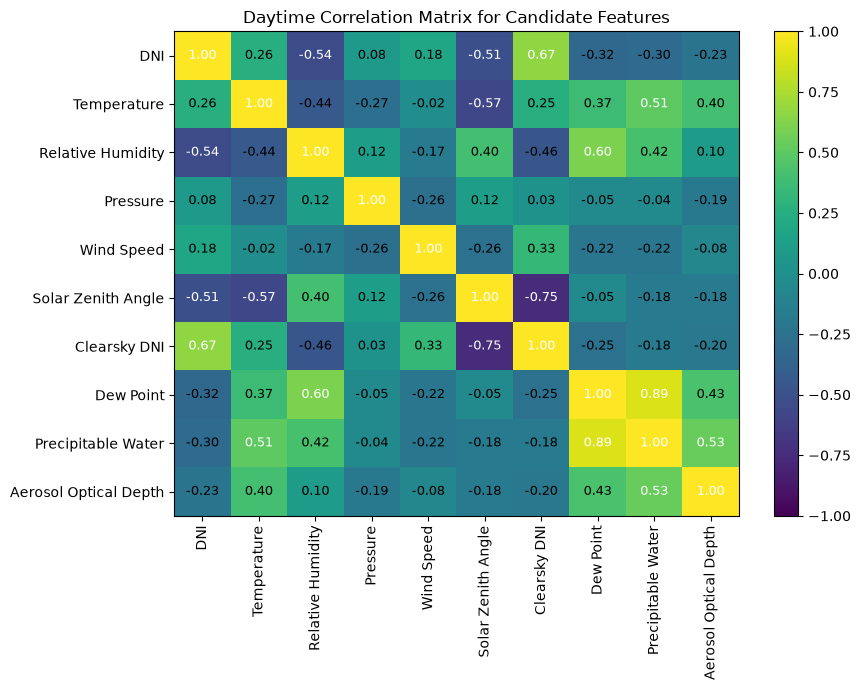

In [14]:
# Correlation matrix for candidate features during daytime only

corr = corr_df.loc[corr_df["is_daytime"] == 1, available_feature_cols_multi_corr].corr()

plt.figure(figsize=(9, 7))
im = plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(im)

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Daytime Correlation Matrix for Candidate Features")

for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        val = corr.iloc[i, j]
        text_color = "white" if abs(val) > 0.5 else "black"
        plt.text(j, i, f"{val:.2f}", ha="center", va="center", color=text_color, fontsize=9)

plt.tight_layout()
plt.show()

In [15]:
# Final model inputs: lagged DNI plus exogenous weather/atmospheric predictors.
# GHI, DHI, clearsky irradiance, and is_daytime are intentionally excluded
# to reduce feature leakage and redundancy.

feature_cols_multi_day = [
    "DNI",
    "Temperature",
    "Relative Humidity",
    "Pressure",
    "Wind Speed",
    "Solar Zenith Angle",
    "Aerosol Optical Depth"
]

In [16]:
train_multi_day = train[["timestamp", "is_daytime"] + feature_cols_multi_day].copy()
validation_multi_day = validation[["timestamp", "is_daytime"] + feature_cols_multi_day].copy()
test_multi_day = test[["timestamp", "is_daytime"] + feature_cols_multi_day].copy()

train_multi_day = train_multi_day.dropna().reset_index(drop=True)
validation_multi_day = validation_multi_day.dropna().reset_index(drop=True)
test_multi_day = test_multi_day.dropna().reset_index(drop=True)

# Scale model inputs only; is_daytime is used only as a daytime-target mask.
feature_scaler_multi_day = MinMaxScaler()
target_scaler_multi_day = MinMaxScaler()

X_train_multi_day_scaled = feature_scaler_multi_day.fit_transform(train_multi_day[feature_cols_multi_day])
X_val_multi_day_scaled = feature_scaler_multi_day.transform(validation_multi_day[feature_cols_multi_day])
X_test_multi_day_scaled = feature_scaler_multi_day.transform(test_multi_day[feature_cols_multi_day])

y_train_multi_day_scaled = target_scaler_multi_day.fit_transform(train_multi_day[[target_col_multi_day]])
y_val_multi_day_scaled = target_scaler_multi_day.transform(validation_multi_day[[target_col_multi_day]])
y_test_multi_day_scaled = target_scaler_multi_day.transform(test_multi_day[[target_col_multi_day]])

train_day_mask_multi_day = train_multi_day["is_daytime"].values
validation_day_mask_multi_day = validation_multi_day["is_daytime"].values
test_day_mask_multi_day = test_multi_day["is_daytime"].values


In [17]:
# Build multivariate sequences
def create_dataset_multi_daytime_only(X_dataset, y_dataset, day_mask, time_step=24):
    X, y = [], []
    for i in range(len(X_dataset) - time_step):
        target_idx = i + time_step
        
        # only keep this sample if the target row is daytime
        if day_mask[target_idx] == 1:
            X.append(X_dataset[i:(i + time_step), :])   # past values of all features
            y.append(y_dataset[target_idx, 0])          # next DNI value
    return np.array(X), np.array(y)
time_step_multi_day = 24
X_train_multi_day, y_train_multi_day = create_dataset_multi_daytime_only(
    X_train_multi_day_scaled, y_train_multi_day_scaled, train_day_mask_multi_day, time_step=time_step_multi_day
)
X_val_multi_day, y_val_multi_day = create_dataset_multi_daytime_only(
    X_val_multi_day_scaled, y_val_multi_day_scaled, validation_day_mask_multi_day, time_step=time_step_multi_day
)
X_test_multi_day, y_test_multi_day = create_dataset_multi_daytime_only(
    X_test_multi_day_scaled, y_test_multi_day_scaled, test_day_mask_multi_day, time_step=time_step_multi_day
)
y_train_multi_day = y_train_multi_day.reshape(-1, 1)
y_val_multi_day = y_val_multi_day.reshape(-1, 1)
y_test_multi_day = y_test_multi_day.reshape(-1, 1)

X_train_multi_day_final = X_train_multi_day
y_train_multi_day_final = y_train_multi_day

print("X_train_multi_day shape:", X_train_multi_day.shape)
print("y_train_multi_day shape:", y_train_multi_day.shape)
print("Train final:", X_train_multi_day_final.shape, y_train_multi_day_final.shape)
print("Validation:", X_val_multi_day.shape, y_val_multi_day.shape)
print("X_test_multi_day shape :", X_test_multi_day.shape)
print("y_test_multi_day shape :", y_test_multi_day.shape)


X_train_multi_day shape: (111023, 24, 7)
y_train_multi_day shape: (111023, 1)
Train final: (111023, 24, 7) (111023, 1)
Validation: (4432, 24, 7) (4432, 1)
X_test_multi_day shape : (4442, 24, 7)
y_test_multi_day shape : (4442, 1)


In [18]:
# Validation data is sequenced from the shared feature store and kept separate from train/test.
print("Train final:", X_train_multi_day_final.shape, y_train_multi_day_final.shape)
print("Validation:", X_val_multi_day.shape, y_val_multi_day.shape)
print("Test:", X_test_multi_day.shape, y_test_multi_day.shape)

Train final: (111023, 24, 7) (111023, 1)
Validation: (4432, 24, 7) (4432, 1)
Test: (4442, 24, 7) (4442, 1)


#### Train multivariate LSTM - daytime

In [19]:
# Save/reload path for the trained daytime multivariate LSTM
models_dir = MODEL_ROOT
models_dir.mkdir(parents=True, exist_ok=True)
model_multi_day_path = models_dir / "model_multi_day.keras"

# Build the multivariate daytime LSTM
model_multi_day = Sequential([
    LSTM(128, input_shape=(X_train_multi_day_final.shape[1], X_train_multi_day_final.shape[2])),
    Dropout(0.2),
    Dense(1)
])

model_multi_day.compile(optimizer="adam", loss="mse", metrics=["mae"])

# Early stopping to prevent overfitting
early_stop_multi_day = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train only if a saved model is not already available
# If the file exists, reload it
if model_multi_day_path.exists():
    print(f"Loading saved model from {model_multi_day_path.relative_to(repo_root)}")
    model_multi_day = load_model(model_multi_day_path)
    history_multi_day = None
elif RUN_CONFIG.reload_mode:
    raise FileNotFoundError(f"Reload mode is on, but saved model is missing: {model_multi_day_path}")
else:
    print("No saved model found. Training daytime multivariate LSTM...")
    history_multi_day = model_multi_day.fit(
        X_train_multi_day_final, y_train_multi_day_final,
        validation_data=(X_val_multi_day, y_val_multi_day),
        epochs=configured_epoch_count(50),
        batch_size=32,
        shuffle=False,
        callbacks=[early_stop_multi_day],
        verbose=1
    )

    model_multi_day.save(model_multi_day_path)
    print(f"Saved model to {model_multi_day_path}")

if history_multi_day is not None:
    print(history_multi_day.history.keys())


Loading saved model from models/model_multi_day.keras


### Model 4: Multivariate LSTM: all timestamps, including nighttime
#### Build multivariate LSTM: all timestamps

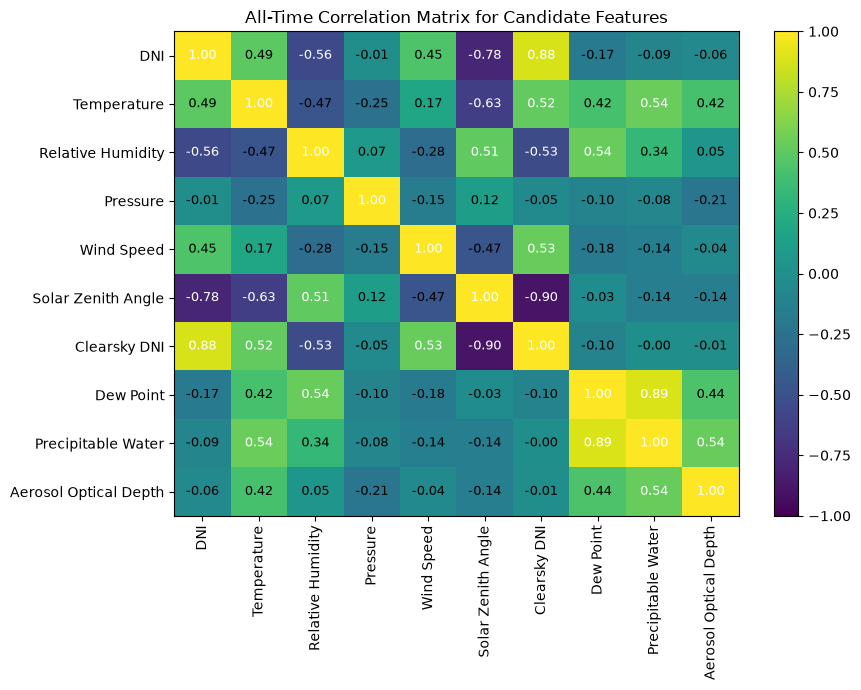

In [20]:
feature_cols_multi_corr = [
    "DNI",
    "Temperature",
    "Relative Humidity",
    "Pressure",
    "Wind Speed",
    "Solar Zenith Angle",
    "Clearsky DNI",
    "Clearsky GHI",
    "Clearsky DHI",
    "Dew Point",
    "Precipitable Water",
    "Aerosol Optical Depth"
]

# Correlation matrix for candidate features across all time

corr = corr_df[available_feature_cols_multi_corr].corr()

plt.figure(figsize=(9, 7))
im = plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(im)

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("All-Time Correlation Matrix for Candidate Features")

for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        val = corr.iloc[i, j]
        text_color = "white" if abs(val) > 0.5 else "black"
        plt.text(
            j,
            i,
            f"{val:.2f}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=9
        )

plt.tight_layout()
plt.show()

In [21]:
target_col_multi_all = "DNI"
feature_cols_multi_all = [
    "DNI",
    "Temperature",
    "Relative Humidity",
    "Pressure",
    "Wind Speed",
    "Solar Zenith Angle",
    "Aerosol Optical Depth"
]

train_multi_all = train[["timestamp"] + feature_cols_multi_all].copy()
validation_multi_all = validation[["timestamp"] + feature_cols_multi_all].copy()
test_multi_all = test[["timestamp"] + feature_cols_multi_all].copy()

train_multi_all = train_multi_all.dropna().reset_index(drop=True)
validation_multi_all = validation_multi_all.dropna().reset_index(drop=True)
test_multi_all = test_multi_all.dropna().reset_index(drop=True)

print("Multivariate all train shape:", train_multi_all.shape)
print("Multivariate all validation shape:", validation_multi_all.shape)
print("Multivariate all test shape :", test_multi_all.shape)


Multivariate all train shape: (218976, 8)
Multivariate all validation shape: (8760, 8)
Multivariate all test shape : (8784, 8)


In [22]:
# Scale features and target
feature_scaler_multi_all = MinMaxScaler()
target_scaler_multi_all = MinMaxScaler()
X_train_multi_all_scaled = feature_scaler_multi_all.fit_transform(
    train_multi_all[feature_cols_multi_all]
)
X_val_multi_all_scaled = feature_scaler_multi_all.transform(
    validation_multi_all[feature_cols_multi_all]
)
X_test_multi_all_scaled = feature_scaler_multi_all.transform(
    test_multi_all[feature_cols_multi_all]
)
y_train_multi_all_scaled = target_scaler_multi_all.fit_transform(
    train_multi_all[[target_col_multi_all]]
)
y_val_multi_all_scaled = target_scaler_multi_all.transform(
    validation_multi_all[[target_col_multi_all]]
)
y_test_multi_all_scaled = target_scaler_multi_all.transform(
    test_multi_all[[target_col_multi_all]]
)


In [23]:
# Build multivariate sequences using all target rows, including nighttime
def create_dataset_multi_all(X_dataset, y_dataset, time_step=24):
    X, y = [], []
    for i in range(len(X_dataset) - time_step):
        target_idx = i + time_step
        X.append(X_dataset[i:(i + time_step), :])
        y.append(y_dataset[target_idx, 0])
    return np.array(X), np.array(y)
time_step_multi_all = 24
X_train_multi_all, y_train_multi_all = create_dataset_multi_all(
    X_train_multi_all_scaled,
    y_train_multi_all_scaled,
    time_step=time_step_multi_all
)
X_val_multi_all, y_val_multi_all = create_dataset_multi_all(
    X_val_multi_all_scaled,
    y_val_multi_all_scaled,
    time_step=time_step_multi_all
)
X_test_multi_all, y_test_multi_all = create_dataset_multi_all(
    X_test_multi_all_scaled,
    y_test_multi_all_scaled,
    time_step=time_step_multi_all
)
y_train_multi_all = y_train_multi_all.reshape(-1, 1)
y_val_multi_all = y_val_multi_all.reshape(-1, 1)
y_test_multi_all = y_test_multi_all.reshape(-1, 1)

X_train_multi_all_final = X_train_multi_all
y_train_multi_all_final = y_train_multi_all

print("X_train_multi_all shape:", X_train_multi_all.shape)
print("y_train_multi_all shape:", y_train_multi_all.shape)
print("X_test_multi_all shape :", X_test_multi_all.shape)
print("y_test_multi_all shape :", y_test_multi_all.shape)

print("Train final:", X_train_multi_all_final.shape, y_train_multi_all_final.shape)
print("Validation:", X_val_multi_all.shape, y_val_multi_all.shape)
print("Test:", X_test_multi_all.shape, y_test_multi_all.shape)

# Build model
model_multi_all = Sequential([
    LSTM(
        128,
        input_shape=(
            X_train_multi_all_final.shape[1],
            X_train_multi_all_final.shape[2]
        )
    ),
    Dropout(0.2),
    Dense(1)
])
model_multi_all.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)
model_multi_all.summary()


X_train_multi_all shape: (218952, 24, 7)
y_train_multi_all shape: (218952, 1)
X_test_multi_all shape : (8760, 24, 7)
y_test_multi_all shape : (8760, 1)
Train final: (218952, 24, 7) (218952, 1)
Validation: (8736, 24, 7) (8736, 1)
Test: (8760, 24, 7) (8760, 1)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 128)            │        69,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,761 (272.50 KB)

 Trainable params: 69,761 (272.50 KB)

 Non-trainable params: 0 (0.00 B)

#### Train multivariate LSTM: all timestamps

In [24]:
# Save/reload path for the trained all-time multivariate LSTM
models_dir = MODEL_ROOT
models_dir.mkdir(parents=True, exist_ok=True)
model_multi_all_path = models_dir / "model_multi_all.keras"

# Early stopping to prevent overfitting
early_stop_multi_all = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train only if a saved model is not already available
# If the file exists, reload it
if model_multi_all_path.exists():
    print(f"Loading saved model from {model_multi_all_path.relative_to(repo_root)}")
    model_multi_all = load_model(model_multi_all_path)
    history_multi_all = None
elif RUN_CONFIG.reload_mode:
    raise FileNotFoundError(f"Reload mode is on, but saved model is missing: {model_multi_all_path}")
else:
    print("No saved model found. Training all-time multivariate LSTM...")
    history_multi_all = model_multi_all.fit(
        X_train_multi_all_final,
        y_train_multi_all_final,
        validation_data=(X_val_multi_all, y_val_multi_all),
        epochs=configured_epoch_count(50),
        batch_size=32,
        shuffle=False,
        callbacks=[early_stop_multi_all],
        verbose=1
    )

    model_multi_all.save(model_multi_all_path)
    print(f"Saved model to {model_multi_all_path}")

# Predict on scaled test sequences
y_pred_multi_all_scaled = model_multi_all.predict(X_test_multi_all)

# Convert predictions and true targets back to original DNI units
y_pred_multi_all = np.clip(
    target_scaler_multi_all.inverse_transform(y_pred_multi_all_scaled),
    dni_lower_bound,
    dni_upper_bound
)
y_test_multi_all_actual = target_scaler_multi_all.inverse_transform(
    y_test_multi_all
)


Loading saved model from models/model_multi_all.keras
  1/274 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step

 28/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 

 58/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

 88/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

118/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

148/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

179/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

210/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

240/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

270/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


### Model Evaluation
The evaluation compares model predictions against actual DNI values and the persistence baseline. Metrics include MAE, MSE, RMSE, NRMSE, R², and MAPE. Additional plots summarize prediction diagnostics, hourly error patterns, seasonal error patterns, and overall model comparisons.


In [25]:
# Evaluation helpers - keep model evaluation logic consistent across all pipelines
def build_eval_df(
    df_with_time,
    y_true,
    y_pred,
    time_step=24,
    timestamp_col="timestamp",
    target_col="DNI",
    daytime_only=False,
    day_col="is_daytime"
):
    # Align each prediction with its target timestamp.
    # If daytime_only=True, keep only samples whose target row is daytime.
    df_eval_base = df_with_time.reset_index(drop=True).copy()
    target_rows = df_eval_base.iloc[time_step:].copy()

    if daytime_only:
        if day_col not in target_rows.columns:
            raise ValueError(f"daytime_only=True requires a '{day_col}' column.")
        target_rows = target_rows.loc[target_rows[day_col] == 1]

    ts = pd.to_datetime(target_rows[timestamp_col]).reset_index(drop=True)
    actual = np.asarray(y_true).reshape(-1)
    predicted = np.asarray(y_pred).reshape(-1)

    if len(ts) != len(actual) or len(ts) != len(predicted):
        raise ValueError(
            "Timestamp, y_true, and y_pred lengths do not match. "
            f"Got timestamps={len(ts)}, y_true={len(actual)}, y_pred={len(predicted)}. "
            "Check whether daytime_only matches the sequence creation logic."
        )

    eval_df = pd.DataFrame({
        "timestamp": ts,
        "actual_dni": actual,
        "predicted_dni": predicted,
    })

    eval_df["error"] = eval_df["predicted_dni"] - eval_df["actual_dni"]
    eval_df["abs_error"] = eval_df["error"].abs()

    # Persistence baseline: previous-hour DNI.
    lookup = df_with_time[[timestamp_col, target_col]].copy()
    lookup[timestamp_col] = pd.to_datetime(lookup[timestamp_col])
    lookup = lookup.groupby(timestamp_col, as_index=False)[target_col].mean()

    eval_df["persistence_dni"] = (
        pd.to_datetime(eval_df["timestamp"]) - pd.Timedelta(hours=1)
    ).map(lookup.set_index(timestamp_col)[target_col])

    eval_df = eval_df.dropna(subset=["persistence_dni"]).reset_index(drop=True)
    eval_df["persistence_error"] = eval_df["persistence_dni"] - eval_df["actual_dni"]
    eval_df["persistence_abs_error"] = eval_df["persistence_error"].abs()
    return eval_df


def build_eval_df_daytime(
    df_with_time,
    y_true,
    y_pred,
    time_step=24,
    timestamp_col="timestamp",
    day_col="is_daytime",
    target_col="DNI"
):
    return build_eval_df(
        df_with_time=df_with_time,
        y_true=y_true,
        y_pred=y_pred,
        time_step=time_step,
        timestamp_col=timestamp_col,
        target_col=target_col,
        daytime_only=True,
        day_col=day_col,
    )


def build_eval_df_all_time(
    df_with_time,
    y_true,
    y_pred,
    time_step=24,
    timestamp_col="timestamp",
    target_col="DNI"
):
    return build_eval_df(
        df_with_time=df_with_time,
        y_true=y_true,
        y_pred=y_pred,
        time_step=time_step,
        timestamp_col=timestamp_col,
        target_col=target_col,
        daytime_only=False,
    )


def compute_eval_metrics(eval_df):
    mae = mean_absolute_error(eval_df["actual_dni"], eval_df["predicted_dni"])
    mse = mean_squared_error(eval_df["actual_dni"], eval_df["predicted_dni"])
    rmse = np.sqrt(mse)
    r2 = r2_score(eval_df["actual_dni"], eval_df["predicted_dni"])
    nrmse = rmse / eval_df["actual_dni"].mean()

    mae_p = mean_absolute_error(eval_df["actual_dni"], eval_df["persistence_dni"])
    mse_p = mean_squared_error(eval_df["actual_dni"], eval_df["persistence_dni"])
    rmse_p = np.sqrt(mse_p)
    r2_p = r2_score(eval_df["actual_dni"], eval_df["persistence_dni"])
    nrmse_p = rmse_p / eval_df["actual_dni"].mean()

    nz = eval_df["actual_dni"] != 0
    mape = (
        (eval_df.loc[nz, "abs_error"] / eval_df.loc[nz, "actual_dni"].abs()).mean() * 100
        if nz.any()
        else np.nan
    )

    return {
        "mae": mae,
        "mse": mse,
        "rmse": rmse,
        "r2": r2,
        "nrmse": nrmse,
        "mape": mape,
        "mae_persistence": mae_p,
        "mse_persistence": mse_p,
        "rmse_persistence": rmse_p,
        "r2_persistence": r2_p,
        "nrmse_persistence": nrmse_p,
    }


def plot_training_curves(history_obj, title_prefix="Model"):
    if history_obj is None:
        return

    hist_df = pd.DataFrame(history_obj.history)
    hist_df["epoch"] = range(1, len(hist_df) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(hist_df["epoch"], hist_df["loss"], label="Training Loss")
    if "val_loss" in hist_df.columns:
        plt.plot(hist_df["epoch"], hist_df["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{title_prefix} Loss per Epoch")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    if "mae" in hist_df.columns:
        plt.figure(figsize=(8, 5))
        plt.plot(hist_df["epoch"], hist_df["mae"], label="Training MAE")
        if "val_mae" in hist_df.columns:
            plt.plot(hist_df["epoch"], hist_df["val_mae"], label="Validation MAE")
        plt.xlabel("Epoch")
        plt.ylabel("MAE")
        plt.title(f"{title_prefix} MAE per Epoch")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()


def _season_name(month):
    if month in [12, 1, 2]:
        return "Winter"
    if month in [3, 4, 5]:
        return "Spring"
    if month in [6, 7, 8]:
        return "Summer"
    return "Fall"


def plot_eval_breakdowns(eval_df, title_prefix="Model"):
    d = eval_df.copy()
    d["timestamp"] = pd.to_datetime(d["timestamp"])

    # MAE by hour of day
    d["hour"] = d["timestamp"].dt.hour
    mae_hour = d.groupby("hour")["abs_error"].mean().reindex(range(24))

    plt.figure(figsize=(10, 4))
    plt.plot(mae_hour.index, mae_hour.values, marker="o")
    plt.title(f"{title_prefix} MAE by Hour of Day")
    plt.xlabel("Hour")
    plt.ylabel("MAE")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # MAE by season
    d["season"] = d["timestamp"].dt.month.map(_season_name)
    season_order = ["Winter", "Spring", "Summer", "Fall"]
    mae_season = d.groupby("season")["abs_error"].mean().reindex(season_order)

    plt.figure(figsize=(7, 4))
    plt.bar(mae_season.index, mae_season.values)
    plt.title(f"{title_prefix} MAE by Season")
    plt.xlabel("Season")
    plt.ylabel("MAE")
    plt.tight_layout()
    plt.show()


def show_largest_misses(eval_df, title_prefix="Model", top_n=10):
    cols = [
        "timestamp",
        "actual_dni",
        "predicted_dni",
        "error",
        "abs_error",
        "persistence_dni",
        "persistence_error",
        "persistence_abs_error",
    ]

    print(f"{title_prefix} - Largest Prediction Misses vs Persistence")
    display(eval_df.nlargest(top_n, "abs_error")[cols])


def plot_prediction_diagnostics(eval_df, title_prefix="Model", sample_n=300):
    d = eval_df.copy()
    d["timestamp"] = pd.to_datetime(d["timestamp"])

    n = min(sample_n, len(d))
    p = d.iloc[:n]

    # Actual vs predicted over time
    plt.figure(figsize=(12, 4))
    plt.plot(p["timestamp"], p["actual_dni"], label="Actual", linewidth=2)
    plt.plot(p["timestamp"], p["predicted_dni"], label="Predicted", linewidth=2)
    plt.title(f"{title_prefix} - Actual vs Predicted")
    plt.xlabel("Timestamp")
    plt.ylabel("DNI")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Scatter plot
    plt.figure(figsize=(6, 6))
    plt.scatter(d["actual_dni"], d["predicted_dni"], alpha=0.3)
    lo = min(d["actual_dni"].min(), d["predicted_dni"].min())
    hi = max(d["actual_dni"].max(), d["predicted_dni"].max())
    plt.plot([lo, hi], [lo, hi], "r--")
    plt.xlabel("Actual DNI")
    plt.ylabel("Predicted DNI")
    plt.title(f"{title_prefix} - Scatter Plot")
    plt.tight_layout()
    plt.show()

    # Residual histogram
    plt.figure(figsize=(8, 4))
    plt.hist(d["error"], bins=40, edgecolor="black")
    plt.xlabel("Residual (Predicted - Actual)")
    plt.ylabel("Count")
    plt.title(f"{title_prefix} - Residual Histogram")
    plt.tight_layout()
    plt.show()


def run_full_evaluation_diagnostics(eval_df, history_obj=None, model_name="Model"):
    plot_training_curves(history_obj, model_name)
    plot_eval_breakdowns(eval_df, model_name)
    show_largest_misses(eval_df, model_name, top_n=10)
    plot_prediction_diagnostics(eval_df, model_name, sample_n=300)

    metrics = compute_eval_metrics(eval_df)

    print(model_name)
    print(f"MAE   : {metrics['mae']:.3f}")
    print(f"MSE   : {metrics['mse']:.3f}")
    print(f"RMSE  : {metrics['rmse']:.3f}")
    print(f"NRMSE : {metrics['nrmse']:.3f}")
    print(f"R²    : {metrics['r2']:.3f}")
    print(f"MAPE  : {metrics['mape']:.3f}%")

    print("Persistence baseline")
    print(f"MAE   : {metrics['mae_persistence']:.3f}")
    print(f"MSE   : {metrics['mse_persistence']:.3f}")
    print(f"RMSE  : {metrics['rmse_persistence']:.3f}")
    print(f"NRMSE : {metrics['nrmse_persistence']:.3f}")
    print(f"R²    : {metrics['r2_persistence']:.3f}")

    return metrics


#### Evaluate Model 1: univariate LSTM: daytime

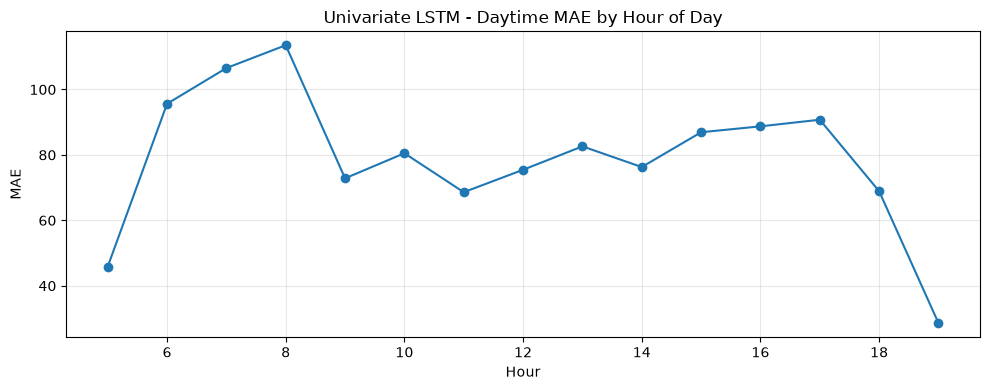

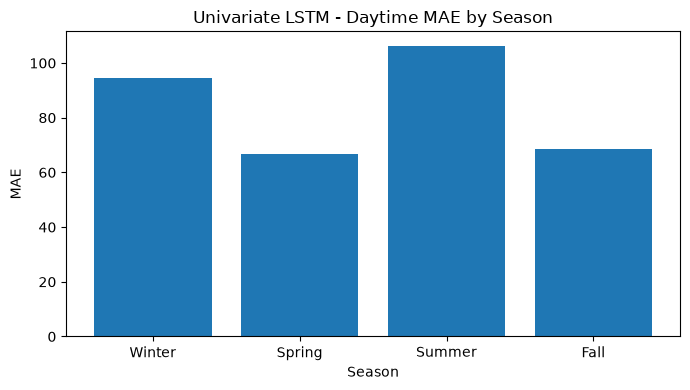

Univariate LSTM - Daytime - Largest Prediction Misses vs Persistence


,timestamp,actual_dni,predicted_dni,error,abs_error,persistence_dni,persistence_error,persistence_abs_error
342,2024-02-02 10:30:00,11.0,875.593445,864.593445,864.593445,820.0,809.0,809.0
2845,2024-08-12 09:30:00,62.0,862.040649,800.040649,800.040649,770.0,708.0,708.0
2822,2024-08-10 12:30:00,29.0,810.905640,781.905640,781.905640,844.0,815.0,815.0
3798,2024-10-29 08:30:00,0.0,731.560730,731.560730,731.560730,441.0,441.0,441.0
2831,2024-08-11 08:30:00,19.0,733.275635,714.275635,714.275635,573.0,554.0,554.0
2904,2024-08-16 16:30:00,28.0,714.986084,686.986084,686.986084,821.0,793.0,793.0
165,2024-01-17 09:30:00,140.0,821.090027,681.090027,681.090027,672.0,532.0,532.0
4063,2024-11-24 08:30:00,16.0,684.956604,668.956604,668.956604,335.0,319.0,319.0
2978,2024-08-22 12:30:00,113.0,779.779907,666.779907,666.779907,856.0,743.0,743.0
847,2024-03-18 16:30:00,54.0,719.332764,665.332764,665.332764,862.0,808.0,808.0


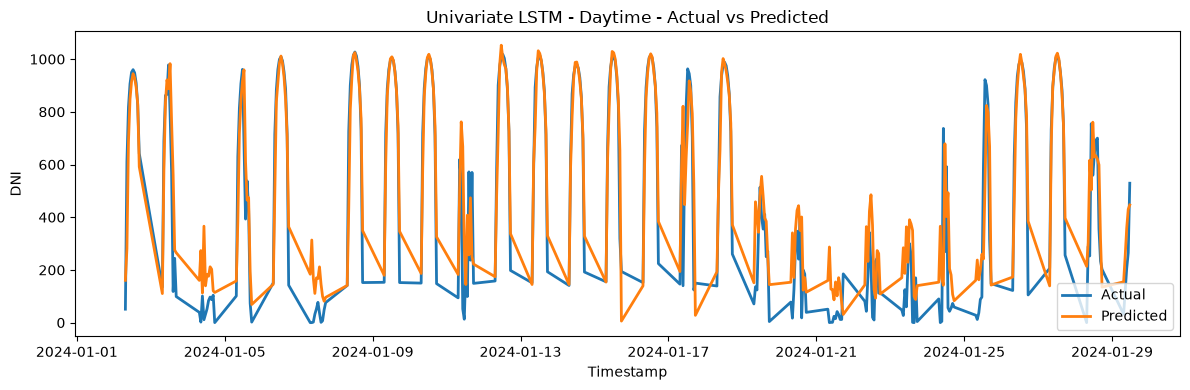

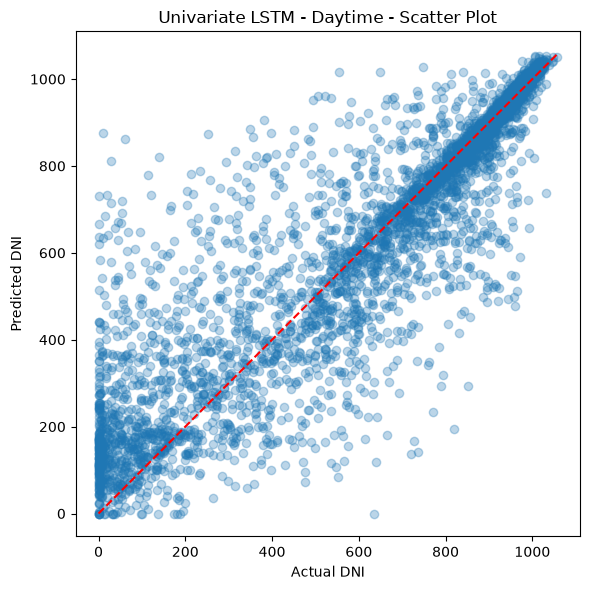

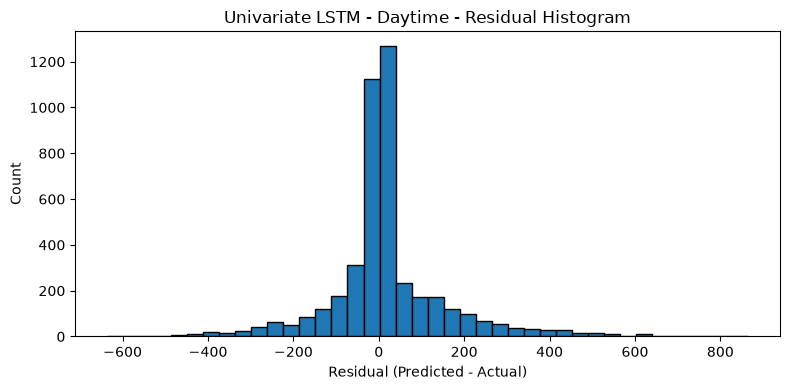

Univariate LSTM - Daytime
MAE   : 84.459
MSE   : 20403.734
RMSE  : 142.842
NRMSE : 0.226
R²    : 0.817
MAPE  : 260.883%
Persistence baseline
MAE   : 148.921
MSE   : 47060.392
RMSE  : 216.934
NRMSE : 0.343
R²    : 0.579


In [26]:
# Build evaluation dataframe for daytime-target univariate model.
eval_df_uni_day = build_eval_df_daytime(
    df_with_time=test,
    y_true=y_true_uni_day,
    y_pred=y_pred_uni_day,
    time_step=time_step_uni_day
)

metrics_uni_day = run_full_evaluation_diagnostics(
    eval_df_uni_day,
    history_uni_day,
    "Univariate LSTM - Daytime"
)

#### Evaluate Model 2: univariate LSTM: all timestamps

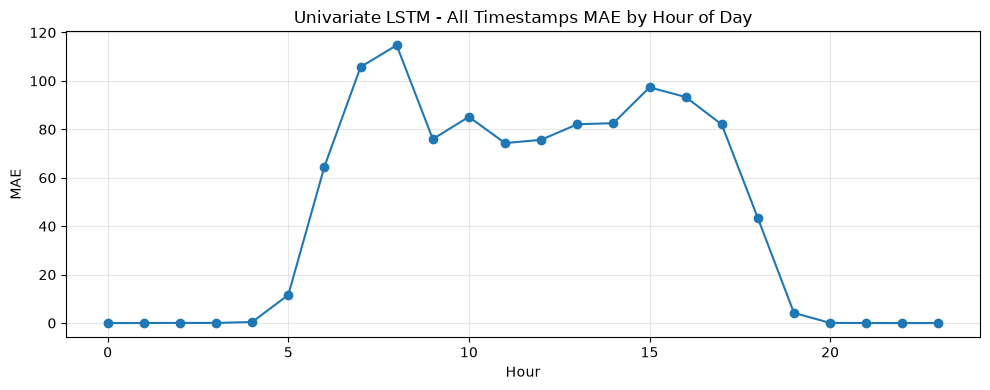

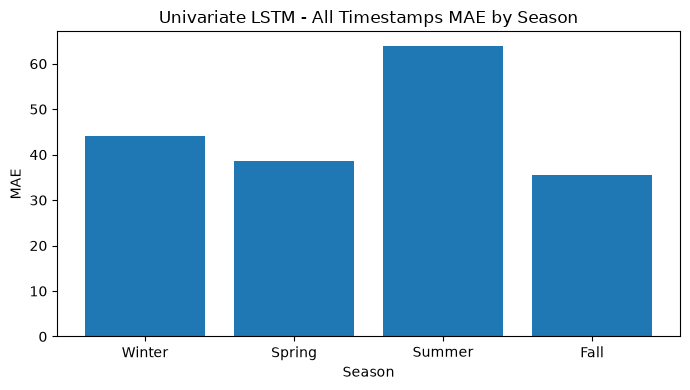

Univariate LSTM - All Timestamps - Largest Prediction Misses vs Persistence


,timestamp,actual_dni,predicted_dni,error,abs_error,persistence_dni,persistence_error,persistence_abs_error
754,2024-02-02 10:30:00,11.0,816.764771,805.764771,805.764771,820.0,809.0,809.0
5316,2024-08-10 12:30:00,29.0,801.552063,772.552063,772.552063,844.0,815.0,815.0
5361,2024-08-12 09:30:00,62.0,815.085022,753.085022,753.085022,770.0,708.0,708.0
7232,2024-10-29 08:30:00,0.0,741.546448,741.546448,741.546448,441.0,441.0,441.0
5336,2024-08-11 08:30:00,19.0,753.329102,734.329102,734.329102,573.0,554.0,554.0
369,2024-01-17 09:30:00,140.0,816.054077,676.054077,676.054077,672.0,532.0,532.0
7856,2024-11-24 08:30:00,16.0,673.691284,657.691284,657.691284,335.0,319.0,319.0
538,2024-01-24 10:30:00,737.0,81.482010,-655.517990,655.517990,5.0,-732.0,732.0
5464,2024-08-16 16:30:00,28.0,682.827515,654.827515,654.827515,821.0,793.0,793.0
1840,2024-03-18 16:30:00,54.0,703.331543,649.331543,649.331543,862.0,808.0,808.0


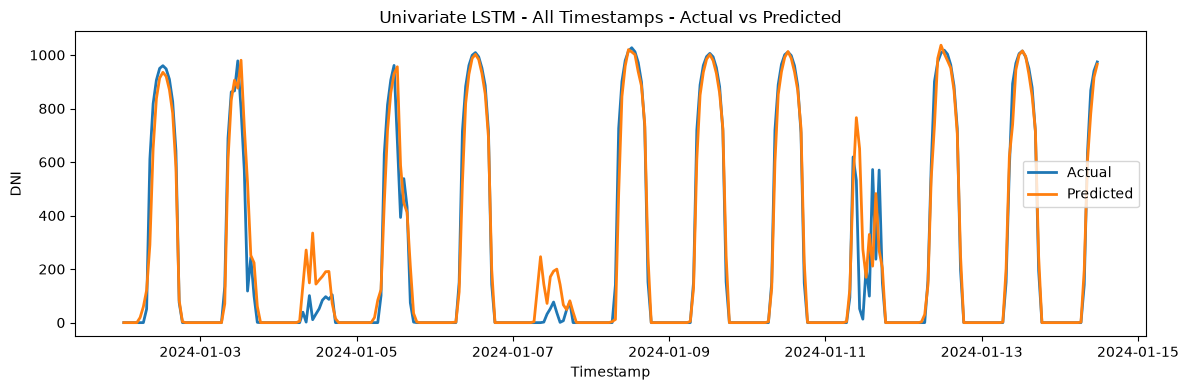

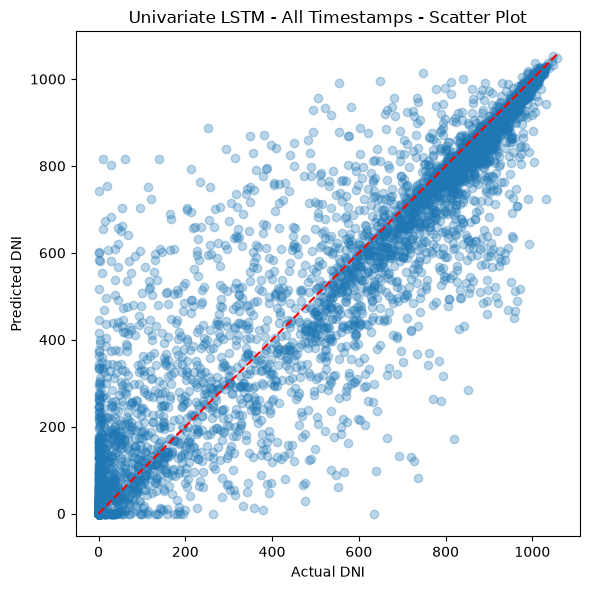

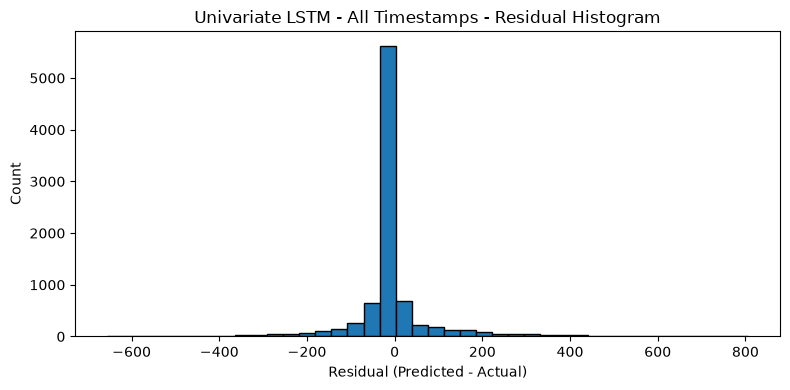

Univariate LSTM - All Timestamps
MAE   : 45.556
MSE   : 10355.768
RMSE  : 101.763
NRMSE : 0.317
R²    : 0.934
MAPE  : 237.068%
Persistence baseline
MAE   : 87.037
MSE   : 28698.089
RMSE  : 169.405
NRMSE : 0.528
R²    : 0.816


In [27]:
# Build evaluation dataframe for univariate LSTM - all timestamps
eval_df_uni_all = build_eval_df_all_time(
    df_with_time=test,
    y_true=y_true_uni_all,
    y_pred=y_pred_uni_all,
    time_step=time_step_uni_all
)

metrics_uni_all = run_full_evaluation_diagnostics(
    eval_df_uni_all,
    history_uni_all,
    "Univariate LSTM - All Timestamps"
)

#### Evaluate Model 3: multivariate LSTM: daytime

In [28]:
# Predict on scaled test sequences
y_pred_multi_day_scaled = model_multi_day.predict(X_test_multi_day)

# Convert predictions and true targets back to original DNI units
y_pred_multi_day = np.clip(
    target_scaler_multi_day.inverse_transform(y_pred_multi_day_scaled),
    dni_lower_bound,
    dni_upper_bound
)

y_test_multi_day_actual = target_scaler_multi_day.inverse_transform(
    y_test_multi_day
)

  1/139 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step

 30/139 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 

 60/139 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

 91/139 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

122/139 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


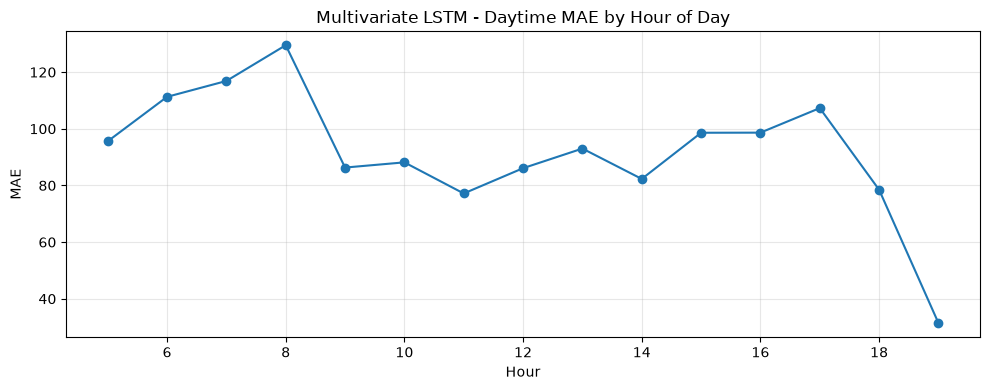

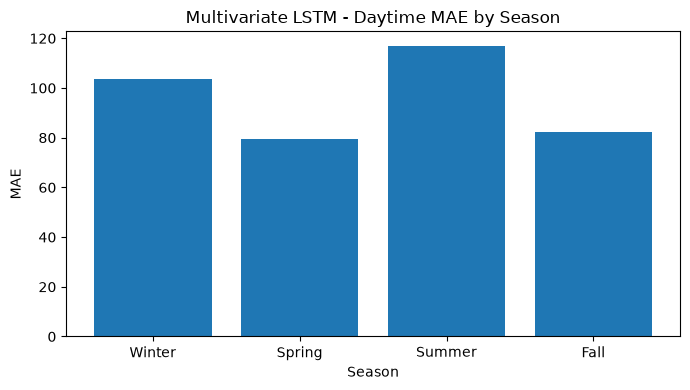

Multivariate LSTM - Daytime - Largest Prediction Misses vs Persistence


,timestamp,actual_dni,predicted_dni,error,abs_error,persistence_dni,persistence_error,persistence_abs_error
2822,2024-08-10 12:30:00,29.0,854.305603,825.305603,825.305603,844.0,815.0,815.0
2845,2024-08-12 09:30:00,62.0,849.876587,787.876587,787.876587,770.0,708.0,708.0
342,2024-02-02 10:30:00,11.0,759.575500,748.575500,748.575500,820.0,809.0,809.0
2978,2024-08-22 12:30:00,113.0,853.592834,740.592834,740.592834,856.0,743.0,743.0
2247,2024-06-29 13:30:00,21.0,739.014099,718.014099,718.014099,688.0,667.0,667.0
2831,2024-08-11 08:30:00,19.0,733.086182,714.086182,714.086182,573.0,554.0,554.0
2734,2024-08-03 15:30:00,0.0,693.649170,693.649170,693.649170,748.0,748.0,748.0
2916,2024-08-17 15:30:00,0.0,692.444946,692.444946,692.444946,752.0,752.0,752.0
3688,2024-10-19 08:30:00,55.0,725.664978,670.664978,670.664978,499.0,444.0,444.0
422,2024-02-09 13:30:00,253.0,922.802002,669.802002,669.802002,945.0,692.0,692.0


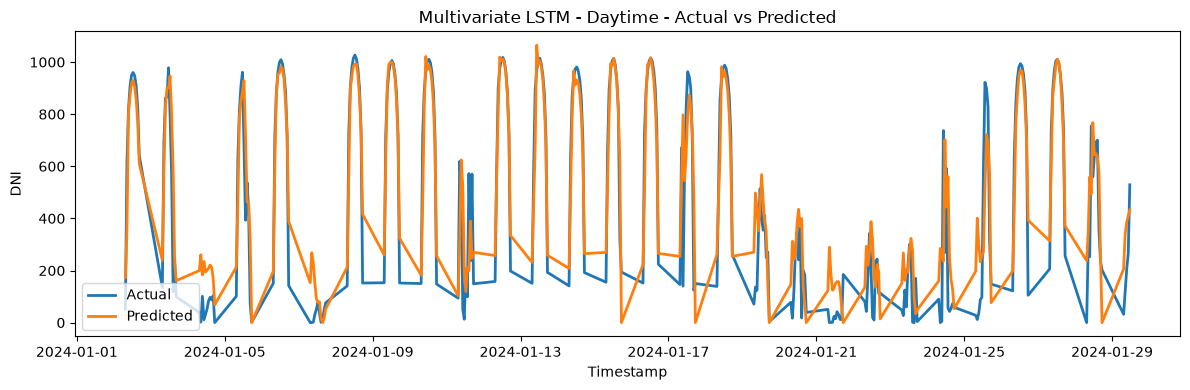

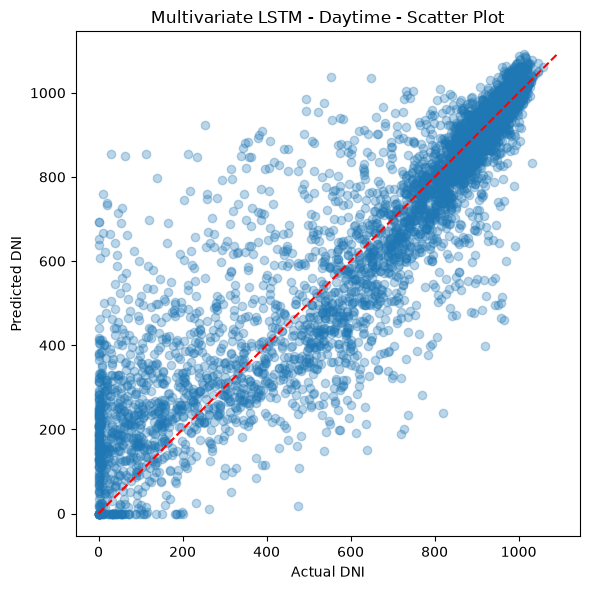

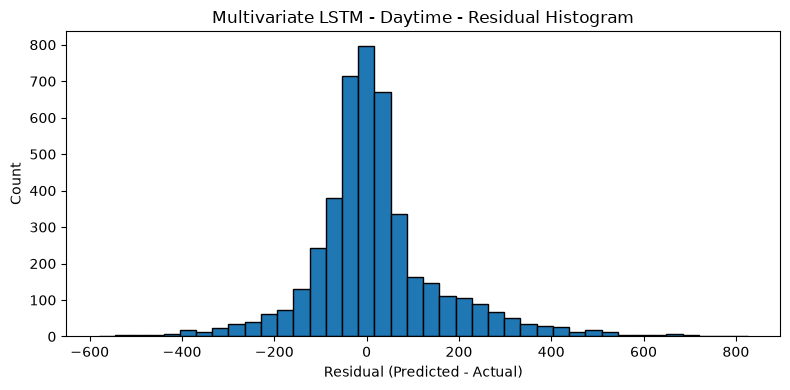

Multivariate LSTM - Daytime
MAE   : 96.060
MSE   : 21252.797
RMSE  : 145.783
NRMSE : 0.231
R²    : 0.810
MAPE  : 289.433%
Persistence baseline
MAE   : 148.921
MSE   : 47060.392
RMSE  : 216.934
NRMSE : 0.343
R²    : 0.579


In [29]:
eval_df_multi_day = build_eval_df_daytime(
    df_with_time=test_multi_day,
    y_true=y_test_multi_day_actual,
    y_pred=y_pred_multi_day,
    time_step=time_step_multi_day,
    timestamp_col="timestamp",
    day_col="is_daytime",
    target_col="DNI"
)

metrics_multi_day = run_full_evaluation_diagnostics(
    eval_df_multi_day,
    history_multi_day,
    "Multivariate LSTM - Daytime"
)

#### Evaluate Model 4: multivariate LSTM: all timestamps

  1/274 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step

 31/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

 61/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

 91/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

121/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

151/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

181/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

211/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

242/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

272/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


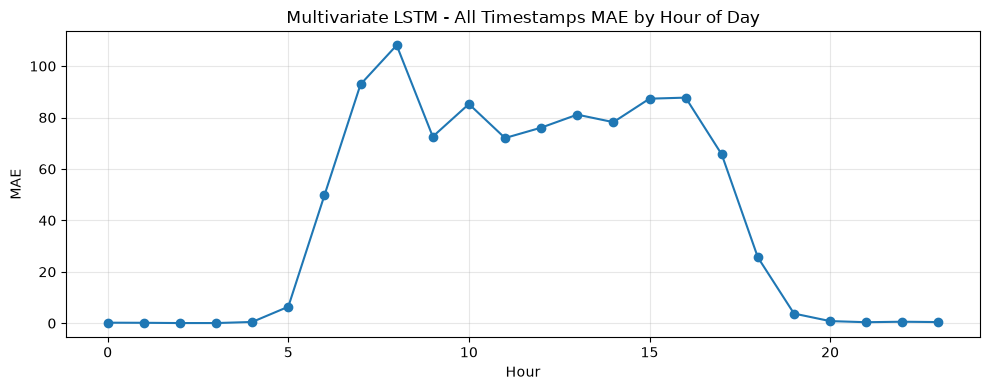

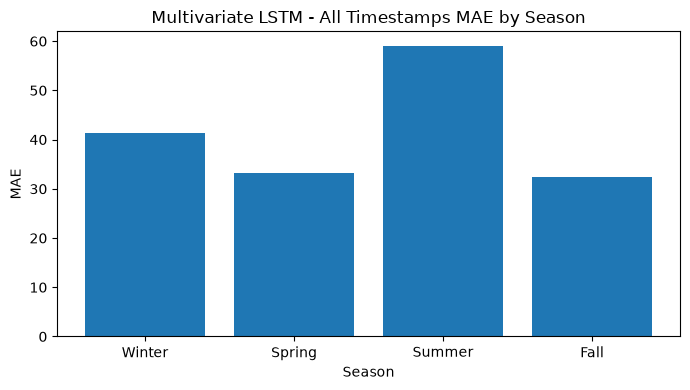

Multivariate LSTM - All Timestamps - Largest Prediction Misses vs Persistence


,timestamp,actual_dni,predicted_dni,error,abs_error,persistence_dni,persistence_error,persistence_abs_error
5316,2024-08-10 12:30:00,29.0,824.851746,795.851746,795.851746,844.0,815.0,815.0
4309,2024-06-29 13:30:00,21.0,813.217529,792.217529,792.217529,688.0,667.0,667.0
5361,2024-08-12 09:30:00,62.0,846.313843,784.313843,784.313843,770.0,708.0,708.0
753,2024-02-02 09:30:00,820.0,119.022659,-700.977341,700.977341,12.0,-808.0,808.0
7856,2024-11-24 08:30:00,16.0,715.586609,699.586609,699.586609,335.0,319.0,319.0
5604,2024-08-22 12:30:00,113.0,803.129272,690.129272,690.129272,856.0,743.0,743.0
5536,2024-08-19 16:30:00,39.0,728.764771,689.764771,689.764771,790.0,751.0,751.0
4264,2024-06-27 16:30:00,46.0,735.471680,689.471680,689.471680,820.0,774.0,774.0
369,2024-01-17 09:30:00,140.0,824.467468,684.467468,684.467468,672.0,532.0,532.0
5487,2024-08-17 15:30:00,0.0,680.779053,680.779053,680.779053,752.0,752.0,752.0


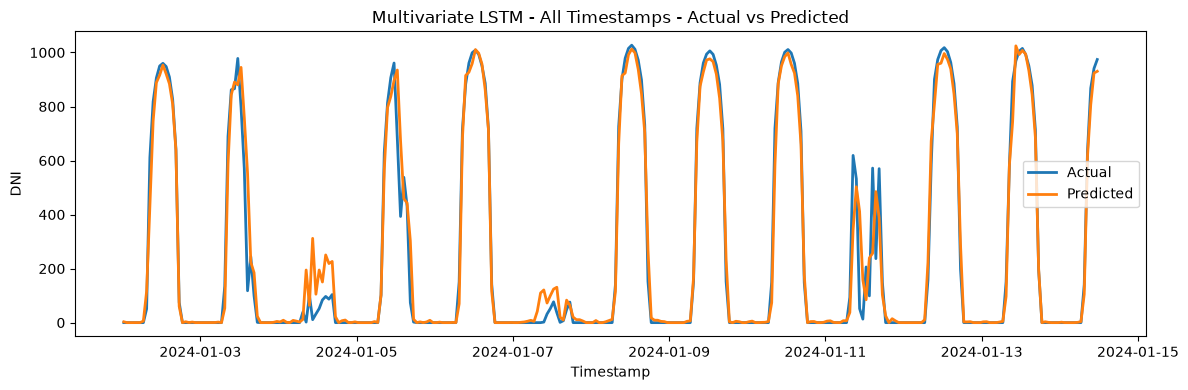

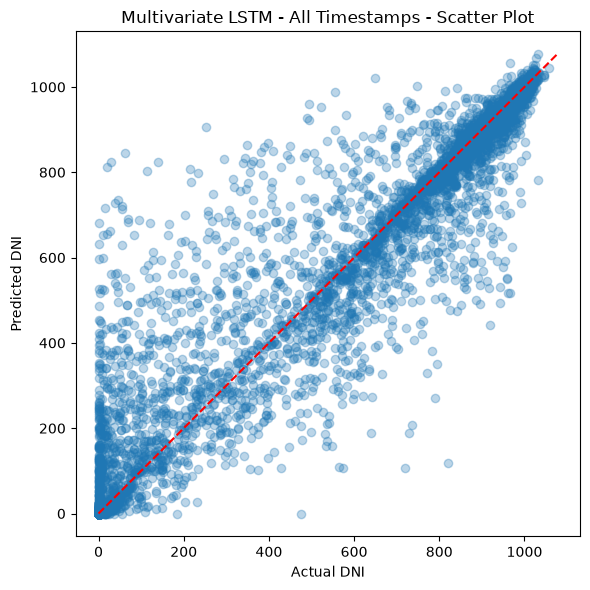

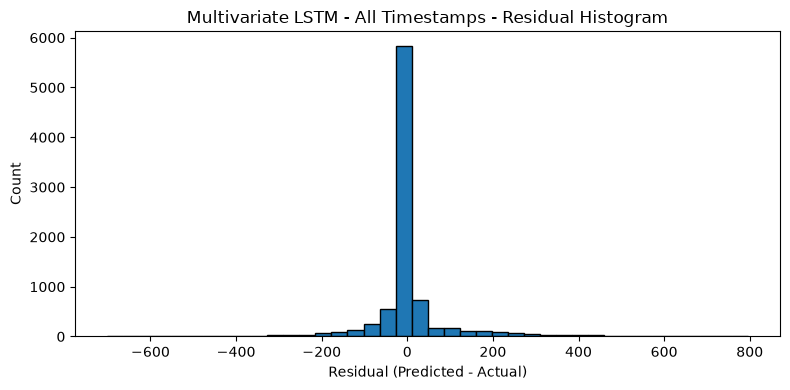

Multivariate LSTM - All Timestamps
MAE   : 41.488
MSE   : 9522.115
RMSE  : 97.581
NRMSE : 0.304
R²    : 0.939
MAPE  : 246.662%
Persistence baseline
MAE   : 87.037
MSE   : 28698.089
RMSE  : 169.405
NRMSE : 0.528
R²    : 0.816


In [30]:
# Predict on scaled test sequences
y_pred_multi_all_scaled = model_multi_all.predict(X_test_multi_all)

# Convert predictions and true targets back to original DNI units
# Clip predictions to physically valid DNI range.
y_pred_multi_all = np.clip(
    target_scaler_multi_all.inverse_transform(y_pred_multi_all_scaled),
    dni_lower_bound,
    dni_upper_bound
)

y_test_multi_all_actual = target_scaler_multi_all.inverse_transform(
    y_test_multi_all
)

# Build eval dataframe and run full diagnostics
eval_df_multi_all = build_eval_df_all_time(
    df_with_time=test_multi_all,
    y_true=y_test_multi_all_actual,
    y_pred=y_pred_multi_all,
    time_step=time_step_multi_all,
    timestamp_col="timestamp",
    target_col="DNI"
)

metrics_multi_all = run_full_evaluation_diagnostics(
    eval_df_multi_all,
    history_multi_all,
    "Multivariate LSTM - All Timestamps"
)


### Comparisons

#### Comparison of the model information with baseline


In [31]:
comparison_results_all = pd.DataFrame([
    {
        "Model": "Persistence Baseline - All",
        "MAE": metrics_uni_all["mae_persistence"],
        "MSE": metrics_uni_all["mse_persistence"],
        "RMSE": metrics_uni_all["rmse_persistence"],
        "NRMSE": metrics_uni_all["nrmse_persistence"],
        "R²": metrics_uni_all["r2_persistence"],
        "MAPE (%)": np.nan
    },
    {
        "Model": "Univariate LSTM - All",
        "MAE": metrics_uni_all["mae"],
        "MSE": metrics_uni_all["mse"],
        "RMSE": metrics_uni_all["rmse"],
        "NRMSE": metrics_uni_all["nrmse"],
        "R²": metrics_uni_all["r2"],
        "MAPE (%)": metrics_uni_all["mape"]
    },
    {
        "Model": "Multivariate LSTM - All",
        "MAE": metrics_multi_all["mae"],
        "MSE": metrics_multi_all["mse"],
        "RMSE": metrics_multi_all["rmse"],
        "NRMSE": metrics_multi_all["nrmse"],
        "R²": metrics_multi_all["r2"],
        "MAPE (%)": metrics_multi_all["mape"]
    },
    {
        "Model": "Persistence Baseline - Daytime Only",
        "MAE": metrics_uni_day["mae_persistence"],
        "MSE": metrics_uni_day["mse_persistence"],
        "RMSE": metrics_uni_day["rmse_persistence"],
        "NRMSE": metrics_uni_day["nrmse_persistence"],
        "R²": metrics_uni_day["r2_persistence"],
        "MAPE (%)": np.nan
    },
    {
        "Model": "Univariate LSTM - Daytime Only",
        "MAE": metrics_uni_day["mae"],
        "MSE": metrics_uni_day["mse"],
        "RMSE": metrics_uni_day["rmse"],
        "NRMSE": metrics_uni_day["nrmse"],
        "R²": metrics_uni_day["r2"],
        "MAPE (%)": metrics_uni_day["mape"]
    },
    {
        "Model": "Multivariate LSTM - Daytime Only",
        "MAE": metrics_multi_day["mae"],
        "MSE": metrics_multi_day["mse"],
        "RMSE": metrics_multi_day["rmse"],
        "NRMSE": metrics_multi_day["nrmse"],
        "R²": metrics_multi_day["r2"],
        "MAPE (%)": metrics_multi_day["mape"]
    }
])

comparison_results_all = comparison_results_all.round({
    "MAE": 3,
    "MSE": 3,
    "RMSE": 3,
    "NRMSE": 3,
    "R²": 3,
    "MAPE (%)": 3
})

display(comparison_results_all)


,Model,MAE,MSE,RMSE,NRMSE,R²,MAPE (%)
0,Persistence Baseline - All,87.037,28698.089,169.405,0.528,0.816,NaN
1,Univariate LSTM - All,45.556,10355.768,101.763,0.317,0.934,237.068
2,Multivariate LSTM - All,41.488,9522.115,97.581,0.304,0.939,246.662
3,Persistence Baseline - Daytime Only,148.921,47060.392,216.934,0.343,0.579,NaN
4,Univariate LSTM - Daytime Only,84.459,20403.734,142.842,0.226,0.817,260.883
5,Multivariate LSTM - Daytime Only,96.060,21252.797,145.783,0.231,0.810,289.433


#### Combined comparison plots
uni daytime, uni all, multi daytime, multi all, baseline

In [32]:
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    if month in [3, 4, 5]:
        return "Spring"
    if month in [6, 7, 8]:
        return "Summer"
    return "Fall"


def prepare_eval_df_for_grouping(eval_df):
    df = eval_df.copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df["hour"] = df["timestamp"].dt.hour
    df["season"] = df["timestamp"].dt.month.apply(get_season)
    return df


def grouped_mae(df, group_col, pred_col="predicted_dni"):
    return (
        df.groupby(group_col)
        .apply(lambda x: mean_absolute_error(x["actual_dni"], x[pred_col]))
    )


# Prepare all evaluation dataframes
eval_df_uni_day_plot = prepare_eval_df_for_grouping(eval_df_uni_day)
eval_df_uni_all_plot = prepare_eval_df_for_grouping(eval_df_uni_all)

eval_df_multi_day_plot = prepare_eval_df_for_grouping(eval_df_multi_day)
eval_df_multi_all_plot = prepare_eval_df_for_grouping(eval_df_multi_all)


# Use the all-time baseline so the baseline covers every hour, including nighttime
baseline_df_plot = eval_df_multi_all_plot.copy()


# Colors: same color for same model family
color_uni = "#1f77b4"       # blue
color_multi = "#ff7f0e"     # orange
color_baseline = "#7f7f7f"  # gray


#### MAE by Hour of Day - Line Graph

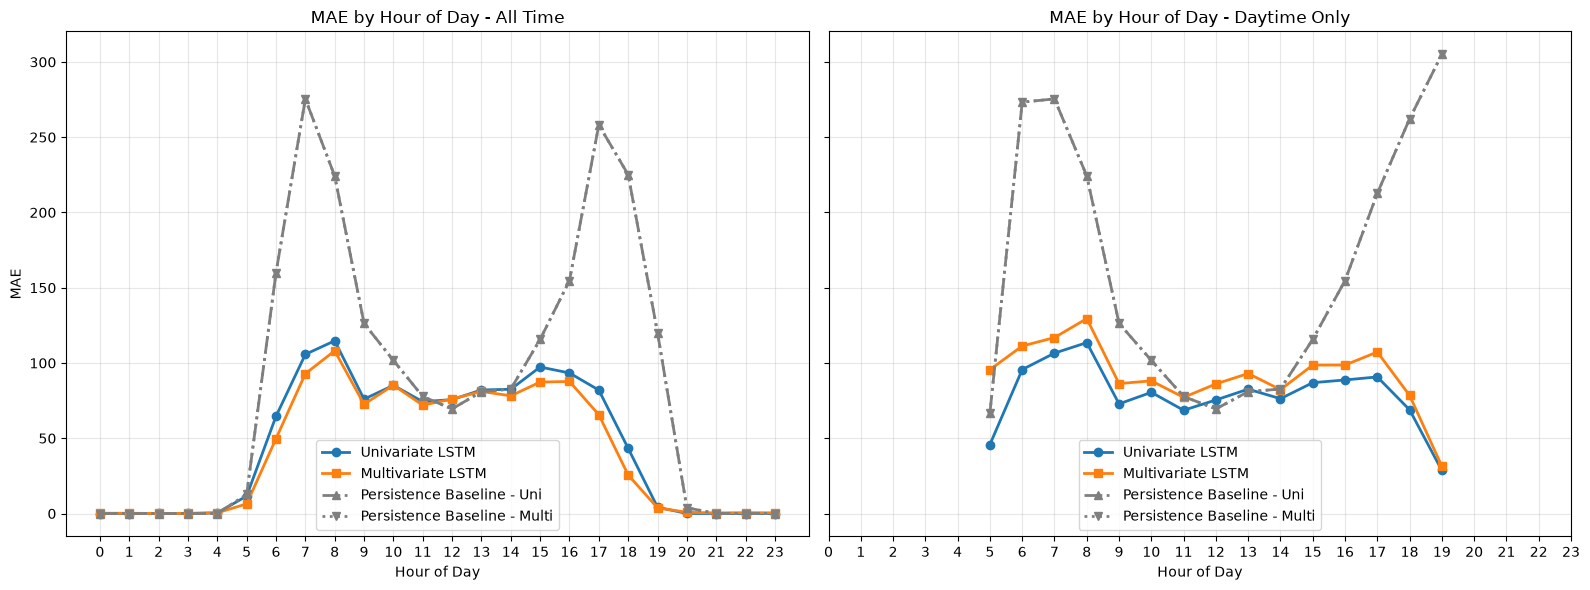

In [33]:
hours = range(24)

mae_hour_uni_day = grouped_mae(eval_df_uni_day_plot, "hour").reindex(hours)
mae_hour_uni_all = grouped_mae(eval_df_uni_all_plot, "hour").reindex(hours)

mae_hour_multi_day = grouped_mae(eval_df_multi_day_plot, "hour").reindex(hours)
mae_hour_multi_all = grouped_mae(eval_df_multi_all_plot, "hour").reindex(hours)

mae_hour_baseline_uni_all = grouped_mae(
    eval_df_uni_all_plot,
    "hour",
    pred_col="persistence_dni"
).reindex(hours)

mae_hour_baseline_multi_all = grouped_mae(
    eval_df_multi_all_plot,
    "hour",
    pred_col="persistence_dni"
).reindex(hours)

mae_hour_baseline_uni_day = grouped_mae(
    eval_df_uni_day_plot,
    "hour",
    pred_col="persistence_dni"
).reindex(hours)

mae_hour_baseline_multi_day = grouped_mae(
    eval_df_multi_day_plot,
    "hour",
    pred_col="persistence_dni"
).reindex(hours)


fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# All Time
axes[0].plot(
    mae_hour_uni_all.index,
    mae_hour_uni_all.values,
    marker="o",
    color=color_uni,
    linestyle="-",
    linewidth=2,
    label="Univariate LSTM"
)

axes[0].plot(
    mae_hour_multi_all.index,
    mae_hour_multi_all.values,
    marker="s",
    color=color_multi,
    linestyle="-",
    linewidth=2,
    label="Multivariate LSTM"
)

axes[0].plot(
    mae_hour_baseline_uni_all.index,
    mae_hour_baseline_uni_all.values,
    marker="^",
    color=color_baseline,
    linestyle="-.",
    linewidth=2,
    label="Persistence Baseline - Uni"
)

axes[0].plot(
    mae_hour_baseline_multi_all.index,
    mae_hour_baseline_multi_all.values,
    marker="v",
    color=color_baseline,
    linestyle=":",
    linewidth=2,
    label="Persistence Baseline - Multi"
)

axes[0].set_title("MAE by Hour of Day - All Time")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("MAE")
axes[0].set_xticks(hours)
axes[0].grid(True, alpha=0.3)
axes[0].legend()


# Daytime Only
axes[1].plot(
    mae_hour_uni_day.index,
    mae_hour_uni_day.values,
    marker="o",
    color=color_uni,
    linestyle="-",
    linewidth=2,
    label="Univariate LSTM"
)

axes[1].plot(
    mae_hour_multi_day.index,
    mae_hour_multi_day.values,
    marker="s",
    color=color_multi,
    linestyle="-",
    linewidth=2,
    label="Multivariate LSTM"
)

axes[1].plot(
    mae_hour_baseline_uni_day.index,
    mae_hour_baseline_uni_day.values,
    marker="^",
    color=color_baseline,
    linestyle="-.",
    linewidth=2,
    label="Persistence Baseline - Uni"
)

axes[1].plot(
    mae_hour_baseline_multi_day.index,
    mae_hour_baseline_multi_day.values,
    marker="v",
    color=color_baseline,
    linestyle=":",
    linewidth=2,
    label="Persistence Baseline - Multi"
)

axes[1].set_title("MAE by Hour of Day - Daytime Only")
axes[1].set_xlabel("Hour of Day")
axes[1].set_xticks(hours)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


#### MAE by Season - Grouped Bar Graph

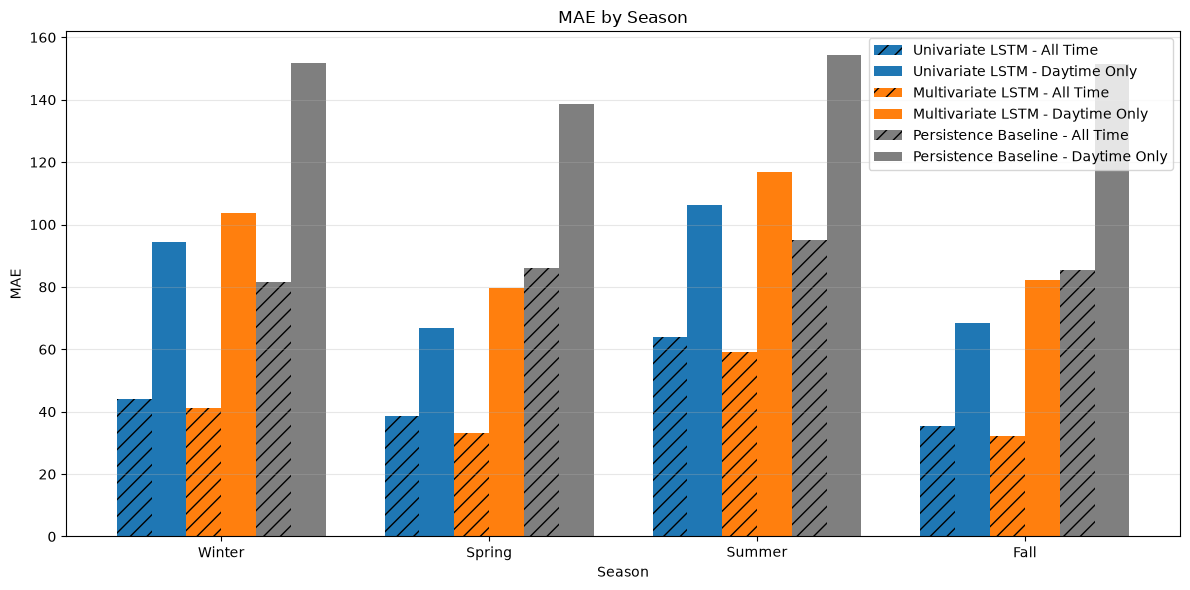

In [34]:
season_order = ["Winter", "Spring", "Summer", "Fall"]

mae_season_uni_day = grouped_mae(eval_df_uni_day_plot, "season").reindex(season_order)
mae_season_uni_all = grouped_mae(eval_df_uni_all_plot, "season").reindex(season_order)

mae_season_multi_day = grouped_mae(eval_df_multi_day_plot, "season").reindex(season_order)
mae_season_multi_all = grouped_mae(eval_df_multi_all_plot, "season").reindex(season_order)

mae_season_baseline_day = grouped_mae(
    eval_df_uni_day_plot,
    "season",
    pred_col="persistence_dni"
).reindex(season_order)

mae_season_baseline_all = grouped_mae(
    eval_df_uni_all_plot,
    "season",
    pred_col="persistence_dni"
).reindex(season_order)


x = np.arange(len(season_order))
bar_width = 0.13

plt.figure(figsize=(12, 6))

plt.bar(
    x - 2.5 * bar_width,
    mae_season_uni_all.values,
    width=bar_width,
    color=color_uni,
    hatch="//",
    label="Univariate LSTM - All Time"
)

plt.bar(
    x - 1.5 * bar_width,
    mae_season_uni_day.values,
    width=bar_width,
    color=color_uni,
    label="Univariate LSTM - Daytime Only"
)

plt.bar(
    x - 0.5 * bar_width,
    mae_season_multi_all.values,
    width=bar_width,
    color=color_multi,
    hatch="//",
    label="Multivariate LSTM - All Time"
)

plt.bar(
    x + 0.5 * bar_width,
    mae_season_multi_day.values,
    width=bar_width,
    color=color_multi,
    label="Multivariate LSTM - Daytime Only"
)

plt.bar(
    x + 1.5 * bar_width,
    mae_season_baseline_all.values,
    width=bar_width,
    color=color_baseline,
    hatch="//",
    label="Persistence Baseline - All Time"
)

plt.bar(
    x + 2.5 * bar_width,
    mae_season_baseline_day.values,
    width=bar_width,
    color=color_baseline,
    label="Persistence Baseline - Daytime Only"
)

plt.title("MAE by Season")
plt.xlabel("Season")
plt.ylabel("MAE")
plt.xticks(x, season_order)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Issues / Improvements
1. LSTM training can take a long time, especially when running all four model setups from scratch. Added "reload" to avoid retraining when not desired.
2. Model checkpoints should be saved after training so models can be reloaded without retraining every notebook session. Implemented by saving models.
3. Additional hyperparameter tuning could compare lookback length, number of LSTM units, dropout, batch size, and learning rate. 
4. Feature selection could be refined further to avoid leakage from solar variables that are highly correlated with DNI. Implemented leakage-proof policy.
5. Future work could compare LSTM results with temporal convolution, transformer-based forecasting, and tree-based baselines.


### References
- National Renewable Energy Laboratory (NREL), National Solar Radiation Database (NSRDB): https://nsrdb.nrel.gov/
- TensorFlow Keras LSTM documentation: https://www.tensorflow.org/api_docs/python/tf/keras/layers/LSTM
- Scikit-learn metrics and preprocessing documentation: https://scikit-learn.org/stable/
- Reference code: https://www.kaggle.com/code/pawan2905/lstm-models-for-time-series-forecasting
